# KNN House Price Regression

Train a K-Nearest Neighbors regression model on `KC_House_Data.csv` to predict house prices.

## 1. Import libraries

In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 2. Load and inspect the house data

In [50]:
df = pd.read_csv('KC_House_Data.csv')
print('Shape:', df.shape)
display(df.head())

Shape: (21613, 20)


,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,20141013T000000,7700000,6,8.00,12050,27600,2.5,0,3,4,13,8570,3480,1910,1987,98102,47.6298,-122.323,3940,8800
1,20140611T000000,7062500,5,4.50,10040,37325,2.0,1,2,3,11,7680,2360,1940,2001,98004,47.6500,-122.214,3930,25449
2,20140919T000000,6885000,6,7.75,9890,31374,2.0,0,4,3,13,8860,1030,2001,0,98039,47.6305,-122.240,4540,42730
3,20140804T000000,5570000,5,5.75,9200,35069,2.0,0,0,3,13,6200,3000,2001,0,98039,47.6289,-122.233,3560,24345
4,20150413T000000,5350000,5,5.00,8000,23985,2.0,0,4,3,12,6720,1280,2009,0,98004,47.6232,-122.220,4600,21750


In [51]:
df.info()
print('\nMissing values:')
display(df.isnull().sum().to_frame('missing_values'))
display(df.describe().T)

<class 'pandas.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           21613 non-null  str    
 1   price          21613 non-null  int64  
 2   bedrooms       21613 non-null  int64  
 3   bathrooms      21613 non-null  float64
 4   sqft_living    21613 non-null  int64  
 5   sqft_lot       21613 non-null  int64  
 6   floors         21613 non-null  float64
 7   waterfront     21613 non-null  int64  
 8   view           21613 non-null  int64  
 9   condition      21613 non-null  int64  
 10  grade          21613 non-null  int64  
 11  sqft_above     21613 non-null  int64  
 12  sqft_basement  21613 non-null  int64  
 13  yr_built       21613 non-null  int64  
 14  yr_renovated   21613 non-null  int64  
 15  zipcode        21613 non-null  int64  
 16  lat            21613 non-null  float64
 17  long           21613 non-null  float64
 18  sqft_living15  21

,missing_values
date,0
price,0
bedrooms,0
bathrooms,0
sqft_living,0
sqft_lot,0
floors,0
waterfront,0
view,0
condition,0


,count,mean,std,min,25%,50%,75%,max
price,21613.0,540088.141767,367127.196483,75000.0000,321950.000,450000.0000,645000.000,7.700000e+06
bedrooms,21613.0,3.370842,0.930062,0.0000,3.000,3.0000,4.000,3.300000e+01
bathrooms,21613.0,2.114757,0.770163,0.0000,1.750,2.2500,2.500,8.000000e+00
sqft_living,21613.0,2079.899736,918.440897,290.0000,1427.000,1910.0000,2550.000,1.354000e+04
sqft_lot,21613.0,15106.967566,41420.511515,520.0000,5040.000,7618.0000,10688.000,1.651359e+06
floors,21613.0,1.494309,0.539989,1.0000,1.000,1.5000,2.000,3.500000e+00
waterfront,21613.0,0.007542,0.086517,0.0000,0.000,0.0000,0.000,1.000000e+00
view,21613.0,0.234303,0.766318,0.0000,0.000,0.0000,0.000,4.000000e+00
condition,21613.0,3.409430,0.650743,1.0000,3.000,3.0000,4.000,5.000000e+00
grade,21613.0,7.656873,1.175459,1.0000,7.000,7.0000,8.000,1.300000e+01


## 3. Prepare features and target

`price` is a continuous target, so this notebook uses `KNeighborsRegressor`. The raw `date` field is converted into year and month. `zipcode` is excluded because its numeric distance does not represent geographic distance; latitude and longitude already provide location information.

In [52]:
df_model = df.copy()
df_model['date'] = pd.to_datetime(df_model['date'], format='%Y%m%dT%H%M%S')
df_model['sale_year'] = df_model['date'].dt.year
df_model['sale_month'] = df_model['date'].dt.month

feature_columns = [
    'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors',
    'waterfront', 'view', 'condition', 'grade', 'sqft_above',
    'sqft_basement', 'yr_built', 'yr_renovated', 'lat', 'long',
    'sqft_living15', 'sqft_lot15', 'sale_year', 'sale_month'
]

X = df_model[feature_columns]
y = df_model['price']

print('Features:', X.shape)
print('Target:', y.shape)

Features: (21613, 19)
Target: (21613,)


## 4. Split the data

In [53]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print('Training rows:', len(X_train))
print('Testing rows:', len(X_test))

Training rows: 17290
Testing rows: 4323


## 5. Select the best value of k

The pipeline fits scaling separately inside every cross-validation fold, which avoids data leakage. Lower RMSE is better.

Best k: 7
Best cross-validated RMSE: $176,727.39


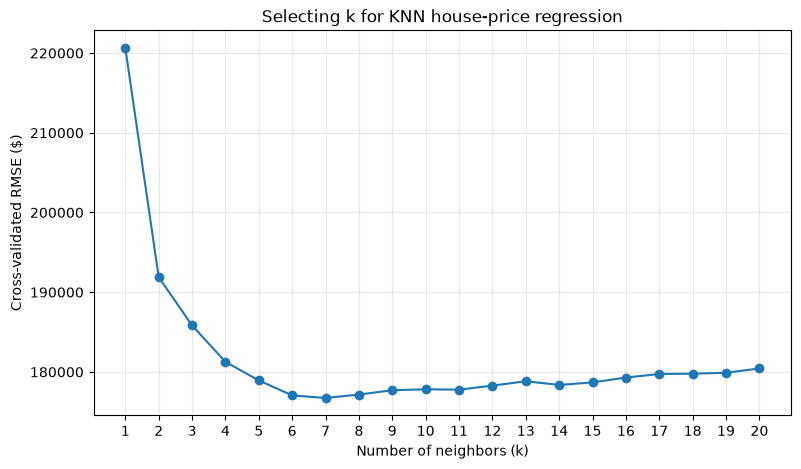

In [54]:
k_values = range(1, 21)
cv_rmse = []

for k in k_values:
    model = Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsRegressor(n_neighbors=k, weights='distance'))
    ])
    neg_mse_scores = cross_val_score(
        model, X_train, y_train, cv=5, scoring='neg_mean_squared_error', n_jobs=-1
    )
    cv_rmse.append(np.sqrt(-neg_mse_scores.mean()))

best_k = list(k_values)[int(np.argmin(cv_rmse))]
print('Best k:', best_k)
print(f'Best cross-validated RMSE: ${min(cv_rmse):,.2f}')

plt.figure(figsize=(9, 5))
plt.plot(list(k_values), cv_rmse, marker='o')
plt.xticks(list(k_values))
plt.xlabel('Number of neighbors (k)')
plt.ylabel('Cross-validated RMSE ($)')
plt.title('Selecting k for KNN house-price regression')
plt.grid(alpha=0.3)
plt.show()

## 6. Train the final model

In [55]:
knn_model = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsRegressor(n_neighbors=best_k, weights='distance'))
])

knn_model.fit(X_train, y_train)
y_pred = knn_model.predict(X_test)

## 7. Evaluate the model

In [56]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f'Mean Absolute Error (MAE): ${mae:,.2f}')
print(f'Root Mean Squared Error (RMSE): ${rmse:,.2f}')
print(f'R-squared (R2): {r2:.4f}')

Mean Absolute Error (MAE): $89,002.30
Root Mean Squared Error (RMSE): $157,028.53
R-squared (R2): 0.7960


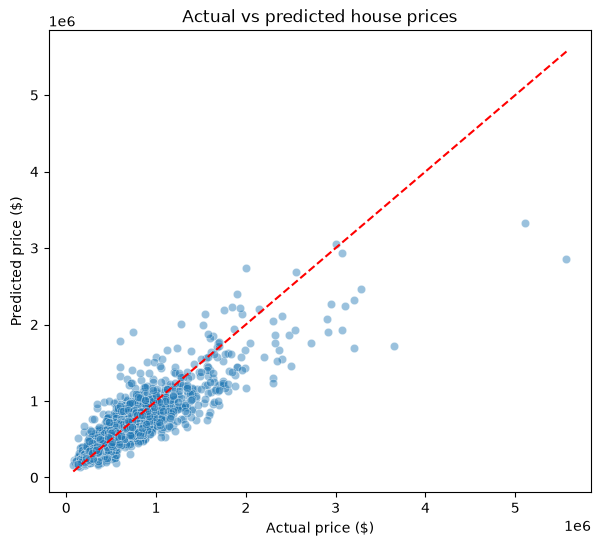

In [57]:
plt.figure(figsize=(7, 6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.45)
line_min = min(y_test.min(), y_pred.min())
line_max = max(y_test.max(), y_pred.max())
plt.plot([line_min, line_max], [line_min, line_max], 'r--')
plt.xlabel('Actual price ($)')
plt.ylabel('Predicted price ($)')
plt.title('Actual vs predicted house prices')
plt.show()

## 8. Review sample predictions

In [58]:
results = X_test.copy()
results['actual_price'] = y_test
results['predicted_price'] = y_pred
results['absolute_error'] = (results['actual_price'] - results['predicted_price']).abs()
display(results[['actual_price', 'predicted_price', 'absolute_error']].head(10))

,actual_price,predicted_price,absolute_error
735,1325000,9.680175e+05,356982.502974
2830,813000,7.748099e+05,38190.109782
4106,718000,5.515055e+05,166494.459353
16218,321000,3.131843e+05,7815.715694
19964,230000,3.439868e+05,113986.811685
1227,1095000,1.177877e+06,82876.871351
18849,260000,2.869084e+05,26908.360115
19369,248500,3.867289e+05,138228.909453
20164,225000,2.110484e+05,13951.587595
7139,568000,5.572159e+05,10784.093416
